# TP3 — Détection d'intrusions réseau : analyse d'un notebook Kaggle et adaptation avec PySpark

## Ma contribution et l'état du notebook

**Notebook étudié :** [UNSW_NB15 | Cybersecurity Threat Detection | ANN — Anmol Gupta](https://www.kaggle.com/code/getanmolgupta01/unsw-nb15-cybersecurity-threat-detection-ann). Je pars de son code original (126 cellules) pour repérer les étapes présentes, partielles ou manquantes, puis je décris mon adaptation sur le [dataset UNSW-NB15](https://www.kaggle.com/datasets/mrwellsdavid/unsw-nb15).

**Le notebook est-il correct et exécutable de bout en bout ?** Le pipeline principal de mon adaptation a été exécuté avec succès dans Google Colab : chargement, analyse des données, prétraitement, transformations, entraînement, évaluation, sauvegarde et inférence. J'ai conservé les sorties de cette exécution. En revanche, **je n'ai pas réexécuté le notebook complet après sa réorganisation**. Les cellules complémentaires de contrôle des doublons et d'évaluation par groupes, ajoutées à la fin, ne sont pas encore exécutées ; je ne prétends donc pas avoir validé une exécution intégrale de toutes les cellules.

**Problèmes et limites rencontrés :**
- Certaines colonnes FTP/HTTP contiennent beaucoup de valeurs absentes ; plusieurs champs du CSV sont initialement importés comme chaînes de caractères, et un nom de colonne contient un espace indésirable.
- Les classes normal/attaque sont déséquilibrées. Le premier découpage aléatoire ne garantit pas l'absence de flux identiques entre les ensembles ; ce risque doit être contrôlé.
- Le notebook Kaggle original applique certaines transformations avant la séparation des données et ne présente pas de véritable test final indépendant après réglage des hyperparamètres.
- L'environnement Colab est temporaire et Spark est utilisé ici en mode local, sans cluster distribué sur plusieurs machines.

**Modifications que j'ai apportées :**
- J'ai étudié le code et les résultats de l'ANN Kaggle, en classant les étapes de la chaîne IA comme présentes, partielles ou manquantes.
- J'ai repris les quatre fichiers CSV bruts avec **PySpark**, normalisé les colonnes et analysé les valeurs manquantes, en conservant des indicateurs d'absence pour les champs FTP/HTTP.
- J'ai ajouté le stockage **Parquet**, l'encodage et la standardisation dans un pipeline Spark MLlib, avec une séparation entre entraînement, validation et test.
- J'ai entraîné un classificateur **binaire** de régression logistique, mesuré les erreurs de détection et ajouté la sauvegarde, le rechargement et l'inférence sans étiquette.
- J'ai prévu un contrôle des doublons entre ensembles et une évaluation complémentaire par groupes, à exécuter séparément.

**Résultats obtenus :** sur les 507 459 connexions du premier jeu de test, j'ai obtenu **97,86 % d'accuracy**, **93,21 % de rappel des attaques**, **91,69 % de F1-score** et **98,64 % de PR-AUC**. Ces résultats concernent la classification **binaire** et ne se comparent pas directement à l'ANN **multiclasse** d'origine. Ils restent à confirmer avec un protocole qui contrôle les doublons.

**Environnement :** Google Colab, Python, PySpark et Spark MLlib (`local[2]`). Les résultats historiques de l'ANN proviennent des sorties enregistrées dans le notebook Kaggle ; je n'ai pas réexécuté cet ANN dans Colab.


## Analyse du notebook Kaggle d’origine

J'ai inspecté les **126 cellules** de la version `.ipynb` fournie, et pas seulement le titre ou la description Kaggle. Voici ce que j'ai retrouvé dans le code.

| Chaîne | État dans l'original | Ce que j'ai vérifié dans les cellules |
|---|---|---|
| **DATA** | **Présent, avec une limite** | Lecture des quatre `UNSW-NB15_*.csv` avec `pd.read_csv`, concaténation et mélange (cellules 4, 15 à 18). Chargement également des fichiers training/testing, sans utilisation ultérieure dans la séparation finale. |
| **EDA** | **Présent** | Dimensions, types, doublons, valeurs manquantes, statistiques descriptives, valeurs uniques, boxplots, histogrammes, distribution des attaques et corrélations (cellules 20 à 41, 56 à 69, 80 à 83). |
| **Prétraitement** | **Présent, partiellement satisfaisant** | Suppression des doublons, remplissage des valeurs manquantes, correction de `ct_ftp_cmd`, traitement de `is_ftp_login`, conversions des ports et outliers (cellules 27 à 54 et 58 à 60). Certains `NULL` sont remplacés par zéro sans conserver l'information d'absence. |
| **Transformations** | **Présent, mais protocole à corriger** | Variables dérivées, encodage de la cible, corrélations, SMOTE + sous-échantillonnage, sélection par information mutuelle, standardisation et PCA (cellules 72 à 102). Le rééquilibrage et la standardisation interviennent **avant** la séparation train/test. |
| **ML** | **Présent** | ANN TensorFlow/Keras à **11 sorties** (*softmax*), entraînement puis recherche d'hyperparamètres avec Keras Tuner (cellules 103 à 124). |
| **EVAL** | **Partiel** | Loss et accuracy, courbes d'entraînement/validation (cellules 109 à 113 et 122 à 124). Le même ensemble `x_test_scaled` sert de validation, d'évaluation et au réglage des hyperparamètres ; pas de véritable test final indépendant après tuning. |
| **Deploy** | **Manquant** | Aucune cellule de sauvegarde/rechargement du modèle ni d'inférence sur des observations sans étiquette. |

### Ce que montre l'exécution enregistrée

- Le chargement/contenu initial affiche **2 540 043 lignes et 49 colonnes** (cellule 21).
- L'auteur compte **480 626 doublons**, puis applique `drop_duplicates()` (cellules 27-28).
- Il ramène les **11 catégories à 15 000 observations chacune** avec SMOTE et sous-échantillonnage, soit 165 000 observations après rééquilibrage ; l'ensemble d'entraînement final comporte **132 000 lignes et 20 caractéristiques** (cellules 87 et 104).
- L'ANN de référence affiche une **accuracy de 70,26 %** sur sa partition dite *test*, avec une loss d'environ **0,903** (cellule 110). Le tuning affiche une meilleure `val_accuracy` d'environ **69,88 %** pendant la recherche (cellule 118), mais je ne retrouve pas d'évaluation indépendante finale du modèle réglé.

### Problèmes à corriger ou à discuter

**Lecture des fichiers.** Les quatre CSV bruts n'ont pas d'en-tête. Dans l'original, `pd.read_csv()` est appelé sans `header=None`, puis les noms de colonnes sont affectés après coup. Le total observé (2 540 043) est inférieur de **quatre lignes** au total que je charge avec Spark (2 540 047), ce qui est cohérent avec la première observation de chacun des quatre fichiers interprétée comme un en-tête. Je vérifie le nombre obtenu mais ne considère pas ces quatre lignes comme des données volontairement exclues.

**Fuite méthodologique.** La cellule 87 rééquilibre le jeu complet avec SMOTE ; la cellule 97 ajuste `StandardScaler` sur ce même ensemble, puis la cellule 102 effectue `train_test_split`. Des informations de la future partition de test interviennent donc avant la séparation. La sélection de caractéristiques est également réalisée avant ce découpage. Les scores ne peuvent pas être interprétés comme ceux d'un test strictement indépendant. L'auteur garde aussi provisoirement `Label` parmi les variables explicatives, avant que cette colonne ne soit éliminée par la sélection (cellules 83 à 94) : cette dépendance indirecte à la sélection rend le protocole fragile.

**Définition de la cible.** Le notebook d'origine prédit **11 familles** via `attack_cat`, alors que mon adaptation prédit **deux classes**, normal (`0`) ou attaque (`1`), via `label`. Je ne peux donc pas présenter **70,26 % → 97,86 %** comme un gain de performance du même modèle : ce sont des tâches et des jeux d'évaluation différents.

**Exécution de l'original.** Je m'appuie sur le code et les sorties déjà conservées dans le `.ipynb` Kaggle : le réseau d'origine **n'a pas été réexécuté par moi** dans Colab. Il faudrait notamment adapter les chemins `/kaggle/input/...`, disposer des dépendances TensorFlow/Keras Tuner et relancer un entraînement long pour vérifier une reproduction indépendante.


### Pourquoi j'ai choisi cette adaptation

L'original contient déjà une EDA, du prétraitement, des transformations et un réseau de neurones. Je n'ai donc pas cherché à présenter ces étapes comme absentes. J'ai plutôt voulu **reprendre le même dataset en mode Big Data**, mieux séparer les étapes d'apprentissage et ajouter ce qui manquait pour réutiliser le modèle.

- Pour **DATA/EDA**, j'utilise PySpark sur les quatre CSV et je travaille sur les agrégations sans charger tout le tableau dans Pandas.
- Pour le **prétraitement**, je conserve une indication lorsque certaines informations FTP/HTTP sont absentes, au lieu de confondre automatiquement une valeur manquante avec zéro.
- Pour les **transformations**, je stocke en Parquet et j'intègre l'encodage ainsi que la standardisation dans un pipeline ajusté seulement sur les données d'entraînement.
- Pour **ML/EVAL**, je traite d'abord la détection **binaire** avec une régression logistique Spark MLlib. Je regarde le rappel, les faux négatifs, le F1-score et la PR-AUC, avec une validation distincte du test.
- Pour **Deploy**, j'ajoute la sauvegarde du pipeline, son rechargement et un exemple d'inférence sans la colonne cible.

Cette approche a toutefois une limite que je veux vérifier : l'original supprime les doublons, alors que mon premier découpage Spark est aléatoire sur les lignes brutes. Même avec des transformations apprises sur le train seulement, **des observations identiques peuvent se retrouver dans le train et le test**. Je garde donc mes performances comme résultat de référence sur ce découpage, pas comme preuve définitive de généralisation.


## Data


### Chargement des données dans Spark

Je télécharge le dataset UNSW-NB15, puis j'initialise une session PySpark. Le mode `local[2]` utilise deux cœurs sur la machine Colab : je bénéficie des DataFrames et des opérations Spark, **sans prétendre disposer d'un cluster multinœud**. Je récupère les quatre CSV bruts pour éviter de me limiter au sous-ensemble d'entraînement/test préconstitué.


In [1]:
%pip install -q kagglehub pyspark

In [2]:
import kagglehub
from pathlib import Path
from pyspark.sql import SparkSession

# Téléchargement du dataset
chemin_data = Path(
    kagglehub.dataset_download("mrwellsdavid/unsw-nb15")
)

print("Dataset :", chemin_data)

for fichier in sorted(chemin_data.rglob("*")):
    if fichier.is_file():
        print(fichier.name,
              round(fichier.stat().st_size / 1024**2, 2),
              "Mo")

# Initialisation d'Apache Spark
spark = (
    SparkSession.builder
    .appName("UNSW_NB15_BigData")
    .master("local[2]")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)

print("Version Spark :", spark.version)

100%|██████████| 149M/149M [00:08<00:00, 18.1MB/s]

Extracting files...


Dataset : /root/.cache/kagglehub/datasets/mrwellsdavid/unsw-nb15/versions/1
NUSW-NB15_features.csv 0.0 Mo
UNSW-NB15_1.csv 161.15 Mo
UNSW-NB15_2.csv 157.57 Mo
UNSW-NB15_3.csv 147.43 Mo
UNSW-NB15_4.csv 93.07 Mo
UNSW-NB15_LIST_EVENTS.csv 0.0 Mo
UNSW_NB15_testing-set.csv 30.8 Mo
UNSW_NB15_training-set.csv 14.67 Mo
Version Spark : 4.0.5


### Lecture des quatre fichiers bruts

Les CSV d'origine n'ont pas d'en-tête. Je les lis donc d'abord sans inférence automatique de schéma, puis je récupère les vrais noms de colonnes depuis le dictionnaire de caractéristiques du dataset. Cela me permet de contrôler explicitement les conversions nécessaires.


In [3]:
from pyspark.sql import functions as F
from pathlib import Path

# Chargement des quatre fichiers complets
fichiers = [
    str(chemin_data / f"UNSW-NB15_{i}.csv")
    for i in range(1, 5)
]

# Vérification des chemins
for fichier in fichiers:
    print(Path(fichier).name, Path(fichier).exists())

# Le dataset brut ne contient pas de noms de colonnes
df_spark = (
    spark.read
    .option("header", "false")
    .option("inferSchema", "false")
    .csv(fichiers)
)

print("Nombre de lignes :", df_spark.count())
print("Nombre de colonnes :", len(df_spark.columns))
print("Nombre de partitions :", df_spark.rdd.getNumPartitions())

df_spark.show(5, truncate=30)

UNSW-NB15_1.csv True
UNSW-NB15_2.csv True
UNSW-NB15_3.csv True
UNSW-NB15_4.csv True
Nombre de lignes : 2540047
Nombre de colonnes : 49
Nombre de partitions : 5
+----------+-----+-------------+----+---+---+--------+---+---+---+----+----+----+----+-----------+-----------+----+----+----+----+----+----+----+----+----+----+-------+---------+----------+----------+-----+--------+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+
|       _c0|  _c1|          _c2| _c3|_c4|_c5|     _c6|_c7|_c8|_c9|_c10|_c11|_c12|_c13|       _c14|       _c15|_c16|_c17|_c18|_c19|_c20|_c21|_c22|_c23|_c24|_c25|   _c26|     _c27|      _c28|      _c29| _c30|    _c31|_c32|_c33|_c34|_c35|_c36|_c37|_c38|_c39|_c40|_c41|_c42|_c43|_c44|_c45|_c46|_c47|_c48|
+----------+-----+-------------+----+---+---+--------+---+---+---+----+----+----+----+-----------+-----------+----+----+----+----+----+----+----+----+----+----+-------+---------+----------+----------+-----+--------+----+----+----+----+---

In [5]:
import pandas as pd
from pathlib import Path
from pyspark.sql import functions as F

# Recherche du fichier contenant les caractéristiques
fichiers_features = list(chemin_data.glob("*features.csv"))

if not fichiers_features:
    raise FileNotFoundError("Fichier des caractéristiques introuvable")

chemin_features = fichiers_features[0]
print("Fichier trouvé :", chemin_features.name)

# Chargement du dictionnaire des caractéristiques
features = pd.read_csv(chemin_features, encoding="latin1")

# Respect de l'ordre des colonnes
features = features.sort_values("No.")

noms_colonnes = (
    features["Name"]
    .str.strip()
    .str.lower()
    .tolist()
)

assert len(noms_colonnes) == 49

# Attribution des vrais noms aux colonnes Spark
df = df_spark.toDF(*noms_colonnes)

print("Nombre de colonnes :", len(df.columns))
print("Colonnes :", df.columns)

# Affichage des caractéristiques réseau
df.select(
    "srcip", "sport", "dstip", "dsport",
    "proto", "state", "attack_cat", "label"
).show(10, truncate=False)

# Répartition du trafic normal et malveillant
df.groupBy("label").count().orderBy("label").show()

Fichier trouvé : NUSW-NB15_features.csv
Nombre de colonnes : 49
Colonnes : ['srcip', 'sport', 'dstip', 'dsport', 'proto', 'state', 'dur', 'sbytes', 'dbytes', 'sttl', 'dttl', 'sloss', 'dloss', 'service', 'sload', 'dload', 'spkts', 'dpkts', 'swin', 'dwin', 'stcpb', 'dtcpb', 'smeansz', 'dmeansz', 'trans_depth', 'res_bdy_len', 'sjit', 'djit', 'stime', 'ltime', 'sintpkt', 'dintpkt', 'tcprtt', 'synack', 'ackdat', 'is_sm_ips_ports', 'ct_state_ttl', 'ct_flw_http_mthd', 'is_ftp_login', 'ct_ftp_cmd', 'ct_srv_src', 'ct_srv_dst', 'ct_dst_ltm', 'ct_src_ ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'attack_cat', 'label']
+-----------+-----+-------------+------+-----+-----+----------+-----+
|srcip      |sport|dstip        |dsport|proto|state|attack_cat|label|
+-----------+-----+-------------+------+-----+-----+----------+-----+
|59.166.0.0 |1390 |149.171.126.6|53    |udp  |CON  |NULL      |0    |
|59.166.0.0 |33661|149.171.126.9|1024  |udp  |CON  |NULL      |0    |
|59.166.0.6 |146

## EDA


### Analyse exploratoire

Après chargement, j'obtiens **2 540 047 lignes**, **49 colonnes** et **5 partitions Spark**. Les deux classes sont très déséquilibrées : environ **87,35 %** de trafic normal contre **12,65 %** de trafic malveillant. Il ne suffira donc pas de regarder l'accuracy : un modèle qui classerait tout comme normal aurait déjà un score élevé sans détecter les attaques.

Je garde les calculs volumineux dans Spark. Seuls les effectifs regroupés sont récupérés dans Pandas pour créer les graphiques.


Répartition par catégorie :
+--------------+-------+
|categorie     |count  |
+--------------+-------+
|Normal        |2218764|
|Generic       |215481 |
|Exploits      |44525  |
|Fuzzers       |24246  |
|DoS           |16353  |
|Reconnaissance|13987  |
|Analysis      |2677   |
|Backdoor      |1795   |
|Shellcode     |1511   |
|Backdoors     |534    |
|Worms         |174    |
+--------------+-------+



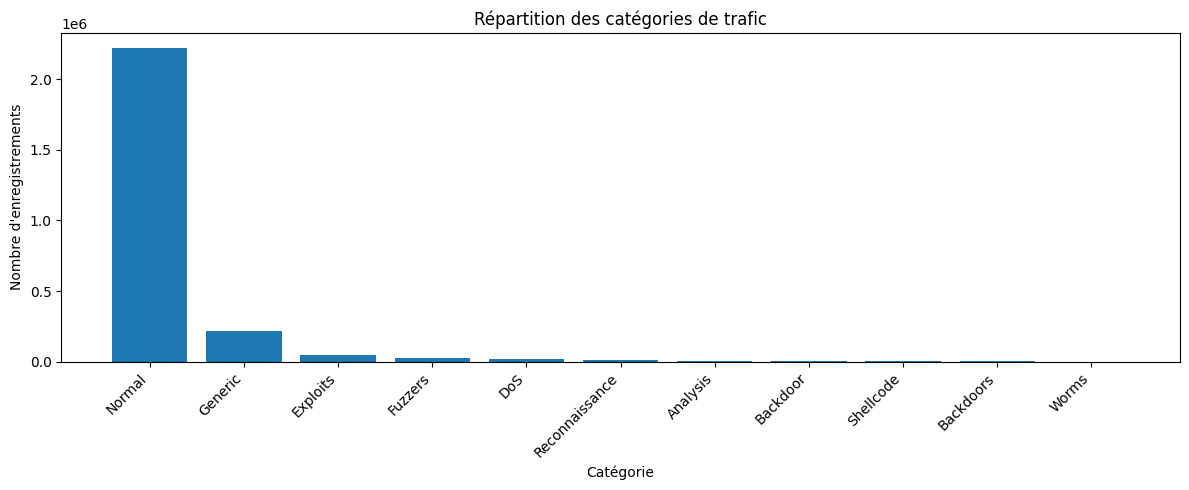

Les 15 protocoles les plus fréquents :
+------+-------+
|proto |count  |
+------+-------+
|tcp   |1495074|
|udp   |990435 |
|unas  |16202  |
|arp   |10064  |
|ospf  |7798   |
|sctp  |1525   |
|icmp  |524    |
|any   |411    |
|gre   |324    |
|rsvp  |274    |
|ipv6  |272    |
|sun-nd|262    |
|pim   |262    |
|swipe |262    |
|mobile|262    |
+------+-------+
only showing top 15 rows
+----------------+--------------------+
|labels_manquants|protocoles_manquants|
+----------------+--------------------+
|               0|                   0|
+----------------+--------------------+



In [6]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

# Répartition des catégories d'attaques
# Les valeurs NULL correspondent au trafic normal.
df_eda = df.withColumn(
    "categorie",
    F.when(
        F.col("attack_cat").isNull()
        | F.upper(F.trim(F.col("attack_cat"))).isin(
            "NULL", "NORMAL", ""
        ),
        "Normal"
    ).otherwise(F.trim(F.col("attack_cat")))
)

attaques = (
    df_eda.groupBy("categorie")
    .count()
    .orderBy(F.desc("count"))
)

print("Répartition par catégorie :")
attaques.show(30, truncate=False)

# Visualisation des effectifs agrégés avec Pandas
attaques_pd = attaques.toPandas()

plt.figure(figsize=(12, 5))
plt.bar(attaques_pd["categorie"], attaques_pd["count"])
plt.title("Répartition des catégories de trafic")
plt.xlabel("Catégorie")
plt.ylabel("Nombre d'enregistrements")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Analyse des protocoles réseau
protocoles = (
    df.groupBy("proto")
    .count()
    .orderBy(F.desc("count"))
)

print("Les 15 protocoles les plus fréquents :")
protocoles.show(15, truncate=False)

# Vérification des valeurs manquantes sur les cibles
df.select(
    F.sum(F.col("label").isNull().cast("int")).alias("labels_manquants"),
    F.sum(F.col("proto").isNull().cast("int")).alias("protocoles_manquants")
).show()

### Visualiser les attaques minoritaires

Sur un graphique commun, le trafic normal masque presque toutes les familles d'attaques. J'ai donc ajouté un graphique réservé aux attaques avec une échelle logarithmique. Je vois notamment que `Generic` est très représentée, alors que `Worms` reste rare. Cette asymétrie est importante pour interpréter plus tard le rappel du classificateur.


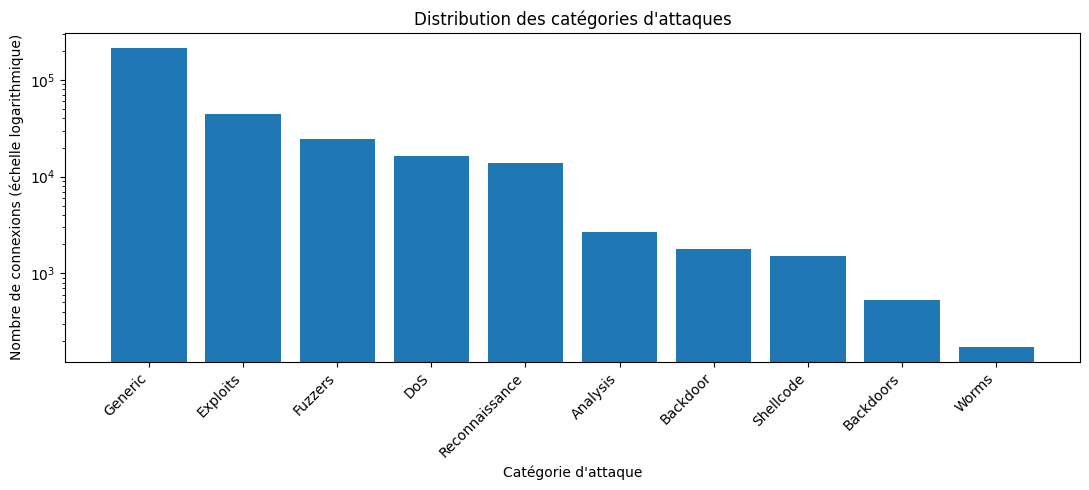

In [7]:
# Je représente séparément les catégories d'attaques,
# car le trafic normal domine le graphique précédent.

attaques_seules = (
    df_eda
    .filter(F.col("label") == "1")
    .groupBy("categorie")
    .count()
    .orderBy(F.desc("count"))
    .toPandas()
)

plt.figure(figsize=(11, 5))

plt.bar(
    attaques_seules["categorie"],
    attaques_seules["count"]
)

plt.yscale("log")
plt.title("Distribution des catégories d'attaques")
plt.xlabel("Catégorie d'attaque")
plt.ylabel("Nombre de connexions (échelle logarithmique)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Analyse de la distribution des attaques

L'analyse exploratoire du dataset met en évidence un déséquilibre important entre le trafic normal et le trafic malveillant. Sur les 2 540 047 observations, environ 87,35 % correspondent à des connexions normales, contre 12,65 % d'attaques.

En observant les catégories d'attaques, je constate également que leur distribution est très inégale. La catégorie Generic est largement majoritaire, tandis que certaines attaques comme Worms et Backdoors sont peu représentées.

Cette distribution risque d'influencer les performances des modèles de classification. Une accuracy élevée ne garantira pas nécessairement une bonne détection des attaques. Je privilégierai donc également le rappel, la précision et le F1-score lors de l'évaluation.

J'ai ajouté une représentation logarithmique des catégories d'attaques afin de mieux visualiser les classes minoritaires.

### Cohérence des étiquettes et premier examen du schéma

Je regarde la correspondance entre les catégories d'attaques et la variable `label`, ainsi que les types des variables numériques. Dans les données brutes, certains noms de catégories commencent par un espace et les 49 colonnes sont importées comme des chaînes de caractères.


In [8]:
from pyspark.sql import functions as F

# Vérification de la cohérence des étiquettes.
print("Correspondance entre catégorie et label :")

df.groupBy("attack_cat", "label") \
  .count() \
  .orderBy(F.desc("count")) \
  .show(30, truncate=False)

# Vérification des types de données.
print("Schéma actuel :")
df.printSchema()

# Vérification de quelques champs numériques importants.
print("Exemples de valeurs numériques :")
df.select(
    "dur", "sbytes", "dbytes",
    "spkts", "dpkts", "sload", "dload"
).show(10, truncate=False)

Correspondance entre catégorie et label :
+----------------+-----+-------+
|attack_cat      |label|count  |
+----------------+-----+-------+
|NULL            |0    |2218764|
|Generic         |1    |215481 |
|Exploits        |1    |44525  |
| Fuzzers        |1    |19195  |
|DoS             |1    |16353  |
| Reconnaissance |1    |12228  |
| Fuzzers        |1    |5051   |
|Analysis        |1    |2677   |
|Backdoor        |1    |1795   |
|Reconnaissance  |1    |1759   |
| Shellcode      |1    |1288   |
|Backdoors       |1    |534    |
|Shellcode       |1    |223    |
|Worms           |1    |174    |
+----------------+-----+-------+

Schéma actuel :
root
 |-- srcip: string (nullable = true)
 |-- sport: string (nullable = true)
 |-- dstip: string (nullable = true)
 |-- dsport: string (nullable = true)
 |-- proto: string (nullable = true)
 |-- state: string (nullable = true)
 |-- dur: string (nullable = true)
 |-- sbytes: string (nullable = true)
 |-- dbytes: string (nullable = true)
 |-- stt

## Prétraitement


### Nettoyage et contrôle des données

Dans l'original, l'auteur commence déjà par nettoyer les valeurs manquantes et les formats. Dans mon cas, je commence par corriger le nom `ct_src_ ltm`, normaliser les champs catégoriels et convertir les variables quantitatives en `double` avec `try_cast`. Cela me permet de compter les valeurs non convertibles au lieu de les ignorer.

Dans l'original, `is_ftp_login` est rendu binaire et les champs FTP/HTTP absents sont remplacés par zéro. Je préfère d'abord regarder les valeurs originales et leur fréquence par service réseau. Je garde `attack_cat` pour l'EDA mais **pas comme variable explicative**, puisque cette colonne est directement liée à l'étiquette binaire à prédire.


In [9]:
from pyspark.sql import functions as F

# Correction du nom contenant un espace
df_clean = df.withColumnRenamed(
    "ct_src_ ltm", "ct_src_ltm"
)

# Normalisation des variables catégorielles
df_clean = (
    df_clean
    .withColumn("proto", F.lower(F.trim("proto")))
    .withColumn("state", F.upper(F.trim("state")))
    .withColumn("service", F.lower(F.trim("service")))
    .withColumn(
        "attack_cat",
        F.when(
            F.col("attack_cat").isNull()
            | F.upper(F.trim("attack_cat")).isin(
                "NULL", "NORMAL", ""
            ),
            F.lit("Normal")
        ).otherwise(F.trim("attack_cat"))
    )
    .withColumn("label", F.expr("try_cast(label AS INT)"))
)

# Identification des caractéristiques quantitatives.
# Les adresses IP et les ports restent à part.
colonnes_non_numeriques = {
    "srcip", "dstip", "sport", "dsport",
    "proto", "state", "service",
    "attack_cat", "label"
}

colonnes_numeriques = [
    c for c in df_clean.columns
    if c not in colonnes_non_numeriques
]

# Conversion des mesures réseau en nombres.
# try_cast retourne NULL si une valeur est invalide.
for colonne in colonnes_numeriques:
    df_clean = df_clean.withColumn(
        colonne,
        F.expr(f"try_cast(`{colonne}` AS DOUBLE)")
    )

print("Nombre de variables numériques :",
      len(colonnes_numeriques))

print("Schéma après conversion :")
df_clean.select(
    "dur", "sbytes", "dbytes",
    "proto", "attack_cat", "label"
).printSchema()

print("Catégories après normalisation :")
df_clean.groupBy("attack_cat", "label") \
    .count() \
    .orderBy(F.desc("count")) \
    .show(20, truncate=False)

Nombre de variables numériques : 40
Schéma après conversion :
root
 |-- dur: double (nullable = true)
 |-- sbytes: double (nullable = true)
 |-- dbytes: double (nullable = true)
 |-- proto: string (nullable = true)
 |-- attack_cat: string (nullable = true)
 |-- label: integer (nullable = true)

Catégories après normalisation :
+--------------+-----+-------+
|attack_cat    |label|count  |
+--------------+-----+-------+
|Normal        |0    |2218764|
|Generic       |1    |215481 |
|Exploits      |1    |44525  |
|Fuzzers       |1    |24246  |
|DoS           |1    |16353  |
|Reconnaissance|1    |13987  |
|Analysis      |1    |2677   |
|Backdoor      |1    |1795   |
|Shellcode     |1    |1511   |
|Backdoors     |1    |534    |
|Worms         |1    |174    |
+--------------+-----+-------+



In [10]:
# Contrôles de cohérence après prétraitement

df_clean.select(
    F.count("*").alias("total_lignes"),

    F.sum(
        F.col("label").isNull().cast("int")
    ).alias("labels_invalides"),

    F.sum(
        F.col("dur").isNull().cast("int")
    ).alias("durees_invalides"),

    F.sum(
        F.col("sbytes").isNull().cast("int")
    ).alias("sbytes_invalides"),

    F.sum(
        (
            (F.col("label") == 0)
            & (F.col("attack_cat") != "Normal")
        ).cast("int")
    ).alias("normaux_incoherents"),

    F.sum(
        (
            (F.col("label") == 1)
            & (F.col("attack_cat") == "Normal")
        ).cast("int")
    ).alias("attaques_incoherentes")
).show()

+------------+----------------+----------------+----------------+-------------------+---------------------+
|total_lignes|labels_invalides|durees_invalides|sbytes_invalides|normaux_incoherents|attaques_incoherentes|
+------------+----------------+----------------+----------------+-------------------+---------------------+
|     2540047|               0|               0|               0|                  0|                    0|
+------------+----------------+----------------+----------------+-------------------+---------------------+



In [11]:
from pyspark.sql import functions as F

# Je vérifie toutes les variables numériques après conversion.
# Je recherche les NULL, NaN et valeurs infinies.

controles = []

for colonne in colonnes_numeriques:
    valeur = F.col(colonne)

    invalide = (
        valeur.isNull()
        | F.isnan(valeur)
        | (F.abs(valeur) == float("inf"))
    )

    controles.append(
        F.sum(
            F.when(invalide, 1).otherwise(0)
        ).alias(colonne)
    )

resultats = df_clean.agg(*controles).first().asDict()

anomalies = {
    colonne: nombre
    for colonne, nombre in resultats.items()
    if nombre > 0
}

print("Variables numériques analysées :", len(resultats))
print("Variables contenant des anomalies :", len(anomalies))

for colonne, nombre in sorted(
    anomalies.items(),
    key=lambda x: x[1],
    reverse=True
):
    print(f"{colonne} : {nombre} valeurs invalides")

if not anomalies:
    print("Aucune valeur numérique invalide détectée.")

Variables numériques analysées : 40
Variables contenant des anomalies : 3
is_ftp_login : 1429879 valeurs invalides
ct_ftp_cmd : 1429879 valeurs invalides
ct_flw_http_mthd : 1348145 valeurs invalides


### Examiner les valeurs manquantes avant de les remplacer

Trois champs nécessitent une analyse particulière : `is_ftp_login` et `ct_ftp_cmd` comportent chacun **1 429 879** valeurs invalides après conversion, tandis que `ct_flw_http_mthd` en comporte **1 348 145**. Comme ils concernent FTP et HTTP, je regarde d'abord les valeurs originales et leur relation avec le service réseau. Je ne supprime pas automatiquement ces lignes : cela ferait disparaître une part importante du dataset.


In [13]:
from pyspark.sql import functions as F

# J'examine les valeurs brutes des trois colonnes
# avant de choisir une stratégie de remplacement.

colonnes_a_verifier = [
    "is_ftp_login",
    "ct_ftp_cmd",
    "ct_flw_http_mthd"
]

for colonne in colonnes_a_verifier:
    print(f"\nValeurs originales : {colonne}")

    (
        df.select(
            F.coalesce(
                F.col(colonne),
                F.lit("<NULL>")
            ).alias("valeur")
        )
        .groupBy("valeur")
        .count()
        .orderBy(F.desc("count"))
        .show(10, truncate=False)
    )

# Je vérifie si les absences sont liées aux services réseau.
print("\nValeurs invalides selon le service :")

expressions = [
    F.sum(
        F.when(
            F.expr(f"try_cast(`{colonne}` AS DOUBLE)").isNull(),
            1
        ).otherwise(0)
    ).alias(f"invalides_{colonne}")
    for colonne in colonnes_a_verifier
]

(
    df.groupBy("service")
    .agg(F.count("*").alias("total"), *expressions)
    .orderBy(F.desc("total"))
    .show(20, truncate=False)
)


Valeurs originales : is_ftp_login
+------+-------+
|valeur|count  |
+------+-------+
|<NULL>|1429879|
|0     |1066593|
|1     |43389  |
|4     |156    |
|2     |30     |
+------+-------+


Valeurs originales : ct_ftp_cmd
+------+-------+
|valeur|count  |
+------+-------+
|      |1429879|
|0     |1066498|
|1     |40077  |
|2     |1264   |
|4     |960    |
|3     |729    |
|6     |332    |
|5     |290    |
|8     |18     |
+------+-------+


Valeurs originales : ct_flw_http_mthd
+------+-------+
|valeur|count  |
+------+-------+
|<NULL>|1348145|
|0     |986791 |
|1     |188008 |
|6     |7902   |
|4     |6564   |
|3     |738    |
|2     |588    |
|5     |430    |
|9     |270    |
|14    |224    |
+------+-------+
only showing top 10 rows

Valeurs invalides selon le service :
+--------+-------+----------------------+--------------------+--------------------------+
|service |total  |invalides_is_ftp_login|invalides_ct_ftp_cmd|invalides_ct_flw_http_mthd|
+--------+-------+------------------

In [14]:
from pyspark.sql import functions as F

# J'étudie les valeurs manquantes selon le service réseau.
colonnes = [
    "is_ftp_login",
    "ct_ftp_cmd",
    "ct_flw_http_mthd"
]

resultats = df.groupBy("service").agg(
    F.count("*").alias("total"),
    *[
        F.sum(
            F.when(
                F.col(c).isNull()
                | (F.trim(F.col(c)) == ""),
                1
            ).otherwise(0)
        ).alias(f"manquants_{c}")
        for c in colonnes
    ]
)

resultats.orderBy(F.desc("total")).show(
    20, truncate=False
)

+--------+-------+----------------------+--------------------+--------------------------+
|service |total  |manquants_is_ftp_login|manquants_ct_ftp_cmd|manquants_ct_flw_http_mthd|
+--------+-------+----------------------+--------------------+--------------------------+
|-       |1246397|596013                |596013              |595228                    |
|dns     |781668 |588156                |588156              |588156                    |
|http    |206273 |111955                |111955              |8044                      |
|ftp-data|125783 |64115                 |64115               |64115                     |
|smtp    |81645  |42800                 |42800               |42800                     |
|ftp     |49090  |1267                  |1267                |24229                     |
|ssh     |47160  |23799                 |23799               |23799                     |
|pop3    |1533   |1327                  |1327                |1327                      |
|dhcp    |

### Ce que je retiens de ces contrôles

Les champs FTP sont plus souvent renseignés pour le service `ftp`, et le champ HTTP est plus souvent renseigné pour `http`, mais les absences ne concernent pas exclusivement les autres protocoles. Je ne peux donc pas supposer que chaque valeur manquante signifie exactement zéro. De plus, `is_ftp_login` comporte aussi quelques valeurs `2` et `4` ; je les conserve telles qu'elles sont, sans les transformer arbitrairement en booléen.

Pour une première référence, je vais donc garder un **indicateur d'absence** par champ et remplacer les valeurs non numériques par zéro. Le modèle pourra ainsi distinguer « zéro observé » de « valeur absente ». Il s'agit d'un choix explicite de modélisation, pas d'une preuve que le champ absent vaut réellement zéro.


## Transformation


### Stockage, préparation et encodage

### Passage au format Parquet

Après nettoyage et conversion des types, j'enregistre les données au format **Parquet avec compression Snappy**. Ce stockage colonnaire conserve le schéma et facilite les lectures de colonnes dans Spark.

L'écriture a pris **115,54 s** et le rechargement suivi d'un `count()` **0,99 s** dans mon exécution. Ce ne sont **pas deux mesures directement comparables** : l'une écrit tout le jeu de données, l'autre peut profiter d'optimisations liées aux métadonnées Parquet. Je n'en déduis donc aucun facteur d'accélération CSV/Parquet.


In [12]:
from pathlib import Path
import time

chemin_parquet = "/content/unsw_nb15_parquet"

# Sauvegarde des données nettoyées
debut = time.perf_counter()

(
    df_clean.write
    .mode("overwrite")
    .option("compression", "snappy")
    .parquet(chemin_parquet)
)

temps_ecriture = time.perf_counter() - debut

print(f"Temps d'écriture Parquet : {temps_ecriture:.2f} s")

# Rechargement des données au format Parquet
debut = time.perf_counter()

df_parquet = spark.read.parquet(chemin_parquet)

nombre_lignes = df_parquet.count()

temps_lecture = time.perf_counter() - debut

print("Nombre de lignes :", nombre_lignes)
print("Nombre de partitions :", df_parquet.rdd.getNumPartitions())
print(f"Lecture et comptage : {temps_lecture:.2f} s")

assert nombre_lignes == 2540047

df_parquet.printSchema()

Temps d'écriture Parquet : 115.54 s
Nombre de lignes : 2540047
Nombre de partitions : 3
Lecture et comptage : 0.99 s
root
 |-- srcip: string (nullable = true)
 |-- sport: string (nullable = true)
 |-- dstip: string (nullable = true)
 |-- dsport: string (nullable = true)
 |-- proto: string (nullable = true)
 |-- state: string (nullable = true)
 |-- dur: double (nullable = true)
 |-- sbytes: double (nullable = true)
 |-- dbytes: double (nullable = true)
 |-- sttl: double (nullable = true)
 |-- dttl: double (nullable = true)
 |-- sloss: double (nullable = true)
 |-- dloss: double (nullable = true)
 |-- service: string (nullable = true)
 |-- sload: double (nullable = true)
 |-- dload: double (nullable = true)
 |-- spkts: double (nullable = true)
 |-- dpkts: double (nullable = true)
 |-- swin: double (nullable = true)
 |-- dwin: double (nullable = true)
 |-- stcpb: double (nullable = true)
 |-- dtcpb: double (nullable = true)
 |-- smeansz: double (nullable = true)
 |-- dmeansz: double (null

### Préparation des variables pour la classification

Je crée un indicateur d'absence pour chacun des trois champs problématiques, puis je remplace les valeurs invalides par zéro en gardant la trace de cette opération. Je retire `attack_cat` et, pour cette première expérience, les IP, les ports et les horodatages `stime`/`ltime`. Je conserve **41 caractéristiques numériques et indicateurs**, ainsi que `proto`, `state` et `service`.

Je réalise un premier découpage aléatoire **80 % train / 20 % test**, puis je prélève la validation dans le train. Dans mon pipeline, les catégories et les statistiques de mise à l'échelle sont ajustées uniquement pendant `fit(train_fit)`, contrairement à la standardisation de l'original qui était appliquée avant `train_test_split`.

**Limite de mon découpage :** je n'ai pas éliminé les doublons avant de séparer les lignes. Ce point doit être contrôlé car deux flux identiques dans le train et le test peuvent surestimer les performances.


In [15]:

from pyspark.sql import functions as F

# Je repars du DataFrame Parquet dont les types ont
# déjà été corrigés.
df_ml = df_parquet

variables_manquantes = [
    "is_ftp_login",
    "ct_ftp_cmd",
    "ct_flw_http_mthd"
]

# Pour chaque variable, je conserve l'information
# de présence ou d'absence avant de remplacer les NULL.
for c in variables_manquantes:
    invalide = (
        F.col(c).isNull()
        | F.isnan(F.col(c))
        | (F.abs(F.col(c)) == float("inf"))
    )

    df_ml = (
        df_ml
        .withColumn(
            c + "_absent",
            F.when(invalide, 1.0).otherwise(0.0)
        )
        .withColumn(
            c,
            F.when(invalide, 0.0).otherwise(F.col(c))
        )
    )

# Traitement des éventuelles catégories manquantes
df_ml = df_ml.fillna({
    "proto": "inconnu",
    "state": "inconnu",
    "service": "inconnu"
})

# Sélection des caractéristiques pour l'apprentissage.
# J'écarte les dates, les IP, les ports et attack_cat
# pour cette première expérience.
numeriques_ml = [
    c for c in colonnes_numeriques
    if c not in {"stime", "ltime"}
]

indicateurs = [
    c + "_absent" for c in variables_manquantes
]

categorielle_ml = ["proto", "state", "service"]

variables_ml = numeriques_ml + indicateurs

df_ml = df_ml.select(
    "label",
    *variables_ml,
    *categorielle_ml
)

print("Variables numériques et indicateurs :", len(variables_ml))
print("Variables catégorielles :", categorielle_ml)
print("Lignes disponibles :", df_ml.count())


Variables numériques et indicateurs : 41
Variables catégorielles : ['proto', 'state', 'service']
Lignes disponibles : 2540047


In [16]:

# Séparation reproductible :
# 80 % entraînement, 20 % test.

train_spark, test_spark = df_ml.randomSplit(
    [0.8, 0.2],
    seed=42
)

print("Entraînement :", train_spark.count())
print("Test :", test_spark.count())

print("\nRépartition des classes - entraînement")
train_spark.groupBy("label").count().orderBy("label").show()

print("\nRépartition des classes - test")
test_spark.groupBy("label").count().orderBy("label").show()


Entraînement : 2032588
Test : 507459

Répartition des classes - entraînement
+-----+-------+
|label|  count|
+-----+-------+
|    0|1775704|
|    1| 256884|
+-----+-------+


Répartition des classes - test
+-----+------+
|label| count|
+-----+------+
|    0|443060|
|    1| 64399|
+-----+------+



### Encodage et standardisation dans le pipeline

Pour les catégories `proto`, `state` et `service`, j'utilise `StringIndexer` puis `OneHotEncoder`. `VectorAssembler` construit le vecteur de caractéristiques et `StandardScaler` met les variables à l'échelle **sans centrer** les vecteurs, pour conserver une représentation creuse. L'ensemble de ces transformations est intégré au pipeline Spark : les valeurs apprises sur l'entraînement sont réutilisées sur la validation et le test.


In [17]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    StringIndexer,
    OneHotEncoder,
    VectorAssembler,
    StandardScaler
)
from pyspark.ml.classification import LogisticRegression
import time

# Séparation d'une validation à partir du TRAIN existant.
# Le jeu TEST reste réservé à l'évaluation finale.
train_fit, validation_spark = train_spark.randomSplit(
    [0.875, 0.125], seed=43
)

# Variables catégorielles
colonnes_index = [c + "_idx" for c in categorielle_ml]
colonnes_ohe = [c + "_ohe" for c in categorielle_ml]

indexeur = StringIndexer(
    inputCols=categorielle_ml,
    outputCols=colonnes_index,
    handleInvalid="keep"
)

encodeur = OneHotEncoder(
    inputCols=colonnes_index,
    outputCols=colonnes_ohe,
    handleInvalid="keep"
)

# Regroupement des caractéristiques
assembleur = VectorAssembler(
    inputCols=variables_ml + colonnes_ohe,
    outputCol="features_raw"
)

# Standardisation sans centrage pour conserver
# l'efficacité des représentations creuses.
normaliseur = StandardScaler(
    inputCol="features_raw",
    outputCol="features",
    withStd=True,
    withMean=False
)

print("Variables numériques :", len(variables_ml))
print("Variables catégorielles :", categorielle_ml)

Variables numériques : 41
Variables catégorielles : ['proto', 'state', 'service']


## ML


### Entraînement du modèle Spark

Le notebook Kaggle entraîne un ANN **multiclasse** à 11 sorties et tente un réglage par Keras Tuner. De mon côté, j'ai choisi une **régression logistique binaire** sous Spark MLlib pour détecter d'abord la présence ou non d'une attaque.

Ce choix rend l'expérience plus simple à interpréter : la classe `1` signifie *attaque*, quelle que soit sa famille. Mon modèle ne sait pas distinguer *Generic*, *Exploits* ou *Worms* entre eux. Je ne compare donc pas directement son accuracy à celle de l'ANN multiclasse.

J'ajuste le pipeline complet sur le sous-ensemble d'entraînement et réserve une validation distincte. L'entraînement enregistré dans Colab a duré **177,32 secondes**.


In [18]:

# Classification binaire :
# 0 = trafic normal
# 1 = attaque

regression = LogisticRegression(
    featuresCol="features",
    labelCol="label",
    predictionCol="prediction",
    maxIter=20,
    regParam=0.05,
    elasticNetParam=0.0,
    standardization=False
)

pipeline = Pipeline(stages=[
    indexeur,
    encodeur,
    assembleur,
    normaliseur,
    regression
])

debut = time.perf_counter()

modele_pipeline = pipeline.fit(train_fit)

duree = time.perf_counter() - debut

print(f"Entraînement terminé en {duree:.2f} secondes")
print("Nombre d'étapes :", len(modele_pipeline.stages))


Entraînement terminé en 177.32 secondes
Nombre d'étapes : 5


## Éval


### Validation et test final

### Validation

Je commence par regarder la matrice de confusion et les mesures de la classe **attaque**. C'est surtout le **rappel** qui m'intéresse : un faux négatif correspond à une attaque que mon modèle a considérée comme normale.


In [19]:

from pyspark.sql import functions as F

# Prédictions sur la validation uniquement.
pred_val = modele_pipeline.transform(validation_spark)

# Matrice de confusion agrégée avec Spark
confusion = (
    pred_val
    .groupBy("label", "prediction")
    .count()
    .orderBy("label", "prediction")
)

confusion.show()

# Mesures calculées à partir de la matrice
cases = {
    (int(r["label"]), int(r["prediction"])): r["count"]
    for r in confusion.collect()
}

TN = cases.get((0, 0), 0)
FP = cases.get((0, 1), 0)
FN = cases.get((1, 0), 0)
TP = cases.get((1, 1), 0)

precision = TP / (TP + FP) if TP + FP else 0
rappel = TP / (TP + FN) if TP + FN else 0
f1 = 2 * precision * rappel / (precision + rappel) if precision + rappel else 0
accuracy = (TP + TN) / (TP + TN + FP + FN)

print(f"Accuracy : {accuracy:.4f}")
print(f"Précision des attaques : {precision:.4f}")
print(f"Rappel des attaques : {rappel:.4f}")
print(f"F1-score attaques : {f1:.4f}")
print(f"Faux négatifs : {FN}")


+-----+----------+------+
|label|prediction| count|
+-----+----------+------+
|    0|       0.0|219087|
|    0|       1.0|  3353|
|    1|       0.0|  2277|
|    1|       1.0| 29883|
+-----+----------+------+

Accuracy : 0.9779
Précision des attaques : 0.8991
Rappel des attaques : 0.9292
F1-score attaques : 0.9139
Faux négatifs : 2277


### Analyse de la validation
J'ai entraîné un modèle de régression logistique à l'aide de Spark MLlib. L'entraînement a nécessité 177,32 secondes sur l'environnement Google Colab.

Sur le jeu de validation, le modèle atteint une accuracy de 97,79 %, une précision de 89,91 %, un rappel de 92,92 % et un F1-score de 91,39 % pour les attaques.

Le rappel constitue une métrique particulièrement importante dans ce contexte, puisqu'il mesure la proportion d'attaques effectivement détectées. La matrice de confusion montre que 2 277 connexions malveillantes ont été classées comme normales.

Ces résultats indiquent que le modèle est capable de reconnaître une grande partie des attaques présentes dans le dataset. Cependant, son évaluation sur des flux répartis aléatoirement ne suffit pas à démontrer sa capacité à généraliser à de nouvelles attaques ou à un environnement réseau différent.

### Test final

Contrairement au notebook original, qui utilise sa partition dite « test » pendant les entraînements et la recherche d'hyperparamètres, je conserve `test_spark` à l'écart des étapes d'ajustement. Je ne change pas le seuil de décision après avoir regardé les résultats et j'utilise les **507 459** lignes de test pour la première évaluation finale de ce modèle.

J'ajoute la **PR-AUC** et la matrice de confusion, car une bonne accuracy ne suffit pas dans un dataset déséquilibré. Cependant, le test ne peut pas être considéré comme totalement indépendant tant que le risque de **doublons entre ensembles** n'a pas été écarté.


In [21]:

from pyspark.sql import functions as F
from pyspark.ml.evaluation import BinaryClassificationEvaluator

# Évaluation sur les 20 % réservés au test.
pred_test = modele_pipeline.transform(test_spark)

matrice_test = (
    pred_test
    .groupBy("label", "prediction")
    .count()
    .orderBy("label", "prediction")
)

matrice_test.show()

cases = {
    (int(r["label"]), int(r["prediction"])): r["count"]
    for r in matrice_test.collect()
}

TN = cases.get((0, 0), 0)
FP = cases.get((0, 1), 0)
FN = cases.get((1, 0), 0)
TP = cases.get((1, 1), 0)

precision = TP / (TP + FP) if TP + FP else 0
rappel = TP / (TP + FN) if TP + FN else 0
f1 = 2 * precision * rappel / (precision + rappel) if precision + rappel else 0
accuracy = (TP + TN) / (TP + TN + FP + FN)

evaluateur = BinaryClassificationEvaluator(
    labelCol="label",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderPR"
)

auc_pr = evaluateur.evaluate(pred_test)

print("\nRÉSULTATS DU TEST FINAL")
print(f"Accuracy : {accuracy:.4f}")
print(f"Précision attaques : {precision:.4f}")
print(f"Rappel attaques : {rappel:.4f}")
print(f"F1-score attaques : {f1:.4f}")
print(f"PR-AUC : {auc_pr:.4f}")
print(f"Faux positifs : {FP}")
print(f"Faux négatifs : {FN}")


+-----+----------+------+
|label|prediction| count|
+-----+----------+------+
|    0|       0.0|436552|
|    0|       1.0|  6508|
|    1|       0.0|  4374|
|    1|       1.0| 60025|
+-----+----------+------+


RÉSULTATS DU TEST FINAL
Accuracy : 0.9786
Précision attaques : 0.9022
Rappel attaques : 0.9321
F1-score attaques : 0.9169
PR-AUC : 0.9864
Faux positifs : 6508
Faux négatifs : 4374


### Résultats et interprétation du test Spark

Sur la séparation aléatoire effectuée, mon modèle obtient **97,86 % d'accuracy**, **90,22 % de précision**, **93,21 % de rappel**, **91,69 % de F1-score** et **98,64 % de PR-AUC** pour la classe attaque. Parmi les **64 399** attaques du test, **60 025** sont détectées et **4 374** sont manquées. Le modèle génère aussi **6 508** fausses alertes sur le trafic normal.

Ces résultats décrivent **mon expérience binaire**, et non une amélioration chiffrée de l'ANN à 11 classes. Ils peuvent être optimistes puisque le découpage est aléatoire et que la présence de doublons entre ensembles n'a pas été vérifiée. Une évaluation temporelle, par groupes de flux ou après dédoublonnage serait plus convaincante.

Je relève également que l'original charge **2 540 043** lignes alors que Spark en charge **2 540 047** : la différence de quatre lignes est cohérente avec la lecture de CSV sans `header=None` dans l'original. Le total souvent annoncé de 2 540 044 reste un écart documentaire distinct, que je ne corrige pas arbitrairement dans les données.


## Déploiement


### Sauvegarde et inférence

### Sauvegarder le pipeline complet

Je sauvegarde **toutes** les étapes ajustées : indexeurs, encodages, assemblage, standardisation et régression logistique. Je recharge ensuite le pipeline pour vérifier qu'il peut prédire sans nouvel entraînement. Le chemin `/content/` se trouve sur le stockage temporaire de Colab : pour réutiliser le modèle après fermeture de la session, il faudra en conserver une copie ailleurs.


In [22]:

from pyspark.ml import PipelineModel

# Sauvegarde de toutes les étapes :
# indexation, encodage, assemblage,
# standardisation et classification.

chemin_modele = "/content/unsw_nb15_spark_model"

modele_pipeline.write().overwrite().save(chemin_modele)

# Vérification du rechargement
modele_recharge = PipelineModel.load(chemin_modele)

exemples = test_spark.limit(5)

resultats = modele_recharge.transform(exemples)

resultats.select(
    "label",
    "prediction",
    "probability"
).show(truncate=False)

print("Pipeline Spark sauvegardé et rechargé.")


+-----+----------+------------------------------------------+
|label|prediction|probability                               |
+-----+----------+------------------------------------------+
|0    |0.0       |[0.9588888281078866,0.04111117189211344]  |
|0    |0.0       |[0.9962265758132338,0.0037734241867661833]|
|0    |0.0       |[0.9962265758132338,0.0037734241867661833]|
|0    |0.0       |[0.8804845981937053,0.11951540180629472]  |
|0    |0.0       |[0.9367073857315915,0.06329261426840849]  |
+-----+----------+------------------------------------------+

Pipeline Spark sauvegardé et rechargé.


### Classifier des connexions sans leur étiquette

Dans une situation d'inférence, la vraie classe n'est pas connue. Je retire donc la colonne `label` avant d'appeler le modèle sauvegardé, puis j'affiche la classe estimée et la probabilité d'attaque. Cette cellule simule l'inférence sur des observations du dataset ; ce n'est pas un outil de surveillance réseau en temps réel.


In [23]:

from pyspark.ml.functions import vector_to_array
from pyspark.sql import functions as F

# Je simule l'arrivée de connexions réseau à classifier.
# Les vraies étiquettes ne sont pas fournies au modèle.
flux_a_analyser = test_spark.drop("label").limit(10)

# Utilisation du pipeline précédemment sauvegardé
modele_deploye = modele_recharge

predictions = modele_deploye.transform(flux_a_analyser)

resultats_deploiement = predictions.select(
    "proto",
    "state",
    "service",
    "dur",
    "sbytes",
    "dbytes",
    F.col("prediction").cast("int").alias("classe_predite"),
    vector_to_array("probability")[1].alias("proba_attaque")
)

resultats_deploiement.show(10, truncate=False)

print("Inférence réalisée sans fournir la colonne label.")


+-----+-----+-------+---+------+------+--------------+---------------------+
|proto|state|service|dur|sbytes|dbytes|classe_predite|proba_attaque        |
+-----+-----+-------+---+------+------+--------------+---------------------+
|icmp |NO   |-      |0.0|28.0  |0.0   |0             |0.04111117189211344  |
|arp  |CON  |-      |0.0|28.0  |46.0  |0             |0.0037734241867661833|
|arp  |CON  |-      |0.0|28.0  |46.0  |0             |0.0037734241867661833|
|arp  |INT  |-      |0.0|46.0  |0.0   |0             |0.11951540180629472  |
|arp  |INT  |-      |0.0|46.0  |0.0   |0             |0.06329261426840849  |
|arp  |INT  |-      |0.0|46.0  |0.0   |0             |0.06329261426840849  |
|arp  |INT  |-      |0.0|46.0  |0.0   |0             |0.06329261426840849  |
|arp  |INT  |-      |0.0|46.0  |0.0   |0             |0.04786571062747624  |
|arp  |INT  |-      |0.0|46.0  |0.0   |0             |0.04786571062747624  |
|arp  |INT  |-      |0.0|46.0  |0.0   |0             |0.04786571062747624  |

### Illustration avec des exemples des deux classes

Pour visualiser plus facilement les réussites et les erreurs, je sélectionne cinq connexions normales et cinq attaques. La classe d'origine sert uniquement à former l'échantillon et à lire le résultat ; **elle est retirée avant la prédiction**. Comme l'échantillon est très petit et choisi volontairement, je ne l'utilise pas pour recalculer les performances globales.


In [24]:

from pyspark.sql import functions as F
from pyspark.ml.functions import vector_to_array

# Sélection de cinq exemples de chaque classe pour la démonstration.
# Les étiquettes servent uniquement à constituer l'échantillon.
normaux = (
    test_spark.filter(F.col("label") == 0)
    .limit(5)
    .withColumn("origine", F.lit("Normal"))
    .drop("label")
)

attaques = (
    test_spark.filter(F.col("label") == 1)
    .limit(5)
    .withColumn("origine", F.lit("Attaque"))
    .drop("label")
)

flux_demo = normaux.unionByName(attaques)

# Le modèle ne reçoit aucune colonne label.
resultats_demo = modele_recharge.transform(flux_demo)

resultats_demo.select(
    "origine",
    "proto",
    "service",
    F.col("prediction").cast("int").alias("prediction"),
    F.round(
        vector_to_array("probability")[1], 4
    ).alias("proba_attaque")
).show(10, truncate=False)


+-------+-----+-------+----------+-------------+
|origine|proto|service|prediction|proba_attaque|
+-------+-----+-------+----------+-------------+
|Normal |icmp |-      |0         |0.0411       |
|Normal |arp  |-      |0         |0.0038       |
|Normal |arp  |-      |0         |0.0038       |
|Normal |arp  |-      |0         |0.1195       |
|Normal |arp  |-      |0         |0.0633       |
|Attaque|udp  |-      |1         |0.6323       |
|Attaque|udp  |-      |1         |0.6333       |
|Attaque|udp  |-      |1         |0.6333       |
|Attaque|udp  |-      |1         |0.7073       |
|Attaque|udp  |-      |0         |0.1187       |
+-------+-----+-------+----------+-------------+



### Démonstration du déploiement

Pour vérifier que mon modèle pouvait être réutilisé après son entraînement, j'ai sauvegardé puis rechargé le pipeline Spark MLlib.

J'ai ensuite sélectionné cinq connexions normales et cinq connexions malveillantes, en retirant la colonne `label` avant de réaliser les prédictions.

Sur ces dix exemples, le modèle a correctement classé les cinq connexions normales et détecté quatre des cinq attaques. Une attaque n'a pas été identifiée, ce qui illustre le problème des faux négatifs dans un système de détection d'intrusions.

Cette expérimentation montre que le pipeline peut réaliser des prédictions sans connaître les véritables étiquettes. Il ne s'agit toutefois pas d'un déploiement en production ni d'une évaluation supplémentaire des performances.

## Bilan : améliorations et limites

| Étape | Ce que l'original faisait déjà | Mon apport avec Spark |
|---|---|---|
| **DATA** | Lecture, concaténation et mélange des CSV dans Pandas | Lecture des quatre fichiers **sans en-tête**, renommage par le dictionnaire des 49 champs, traitement sur Spark en mode local. |
| **EDA** | Statistiques, doublons, graphes, corrélations et distributions | Agrégations PySpark sur 2,54 millions de lignes ; focus sur le déséquilibre des attaques et des protocoles. |
| **Prétraitement** | Suppression de doublons, valeurs manquantes remplacées et conversions | Conversions explicites avec contrôle d'erreur et **indicateurs d'absence** pour les trois champs FTP/HTTP. Je dois encore contrôler les doublons entre ensembles. |
| **Transformations** | Variables dérivées, SMOTE, sélection, standardisation, PCA | Parquet Snappy ; `StringIndexer`, `OneHotEncoder`, `VectorAssembler`, `StandardScaler` ajustés dans le pipeline sur **train seulement**. Je n'ai pas reproduit SMOTE ni le feature engineering d'origine. |
| **ML** | ANN Keras avec 11 catégories et recherche d'hyperparamètres | Régression logistique Spark MLlib sur une **cible binaire**. C'est une autre tâche, pas une comparaison d'accuracy à conditions égales. |
| **EVAL** | Loss, accuracy et courbes ; validation/test réutilisé pendant le tuning | Jeu de validation à part, test non utilisé pour ajuster le modèle, matrice de confusion, précision, rappel, F1 et PR-AUC. Reste à contrôler la séparation des doublons. |
| **Deploy** | Rien de réutilisable repéré | Sauvegarde et rechargement du pipeline complet, prédictions sans étiquette. |

### Ce que j'en retiens

L'intérêt principal de mon adaptation est d'utiliser **Spark** pour toute la chaîne, de mieux isoler les transformations apprises et de compléter la phase **Deploy**. Sur mon premier découpage, j'obtiens un rappel de **93,21 %** pour la classe attaque. Je garde toutefois deux réserves : je n'ai pas prouvé l'absence de doublons entre train et test, et mon modèle ne prédit pas les 11 catégories de l'ANN original.

L'exécution de l'ANN initial est visible dans le `.ipynb` fourni, mais **je ne l'ai pas rejouée moi-même**. Mes conclusions sur son fonctionnement viennent donc de la lecture du code et de ses sorties enregistrées. Spark a été utilisé en **mode local sur Colab** : ce projet illustre le traitement Big Data avec Spark, pas un cluster Hadoop réparti sur plusieurs machines.


### Contrôle complémentaire : doublons entre entraînement et test

L'auteur du notebook Kaggle comptait puis supprimait **480 626 doublons** avant l'entraînement. Dans mon premier pipeline Spark, j'ai conservé les observations brutes et effectué `randomSplit`. Pour vérifier une limite possible de mon évaluation, je recherche les **empreintes de caractéristiques identiques** présentes dans les deux ensembles.

Je construis l'empreinte sur **toutes les colonnes effectivement utilisées pour prédire**, sans inclure `label`. Ce contrôle repère des lignes identiques du point de vue du modèle ; des collisions de hachage sont théoriquement possibles, et ce contrôle ne repère pas tous les flux corrélés. Il ne modifie ni les données ni les métriques déjà produites.

Si des empreintes communes sont détectées, il faudra refaire une séparation qui maintient les flux identiques dans un seul ensemble, puis **réentraîner et réévaluer** le modèle. Je ne remplacerai pas mes résultats actuels par des chiffres non mesurés.

In [ ]:
from pyspark.sql import functions as F

# Je cherche les flux ayant exactement les mêmes caractéristiques
# à l'entrée du modèle, sans utiliser le label.
colonnes_empreinte = sorted(
    c for c in train_spark.columns if c != "label"
)

empreintes_train = (
    train_spark
    .select(F.xxhash64(*[F.col(c) for c in colonnes_empreinte]).alias("empreinte"))
    .distinct()
)
empreintes_test = (
    test_spark
    .select(F.xxhash64(*[F.col(c) for c in colonnes_empreinte]).alias("empreinte"))
    .distinct()
)

communes = empreintes_test.join(
    empreintes_train, on="empreinte", how="inner"
).count()

print("Empreintes de caractéristiques communes train/test :", communes)
print("Ce nombre mesure des empreintes distinctes, pas des lignes dupliquées.")
if communes > 0:
    print("Risque de surestimation : une séparation par groupes est à tester.")
else:
    print("Pas d'empreinte identique détectée ; les flux proches restent possibles.")

### Réévaluation possible avec séparation par empreinte de flux

Si le contrôle précédent montre des caractéristiques identiques entre l'entraînement et le test, je peux refaire le protocole de façon plus stricte. Au lieu de tirer les **lignes** au hasard, j'affecte toutes les lignes ayant la même empreinte de caractéristiques à **une seule partition**. Cela évite la fuite de lignes exactement identiques, même si des flux similaires non identiques peuvent toujours exister.

Je conserve trois ensembles : environ **70 % pour entraîner**, **10 % pour valider** et **20 % pour tester**. Les proportions sont approximatives, car les groupes n'ont pas tous la même taille. Ce protocole constitue une expérience complémentaire : **il n'a pas encore été exécuté et les résultats présentés plus haut ne sont pas ceux de cette séparation**.

Si je lance ce nouveau protocole, je dois réentraîner le pipeline depuis le début, puis comparer les résultats. Je ne dois pas réutiliser le modèle déjà ajusté sur l'ancien découpage.

In [ ]:
from pyspark.sql import functions as F

# Les lignes possédant les mêmes caractéristiques vont dans le même ensemble.
empreinte = F.xxhash64(*[F.col(c) for c in colonnes_empreinte])

df_par_groupes = (
    df_ml
    .withColumn("_empreinte", empreinte)
    .withColumn(
        "_bloc",
        F.pmod(F.xxhash64(F.col("_empreinte"), F.lit(42)), F.lit(100))
    )
)

train_groupes = df_par_groupes.filter(F.col("_bloc") < 70).drop("_empreinte", "_bloc")
validation_groupes = df_par_groupes.filter(
    (F.col("_bloc") >= 70) & (F.col("_bloc") < 80)
).drop("_empreinte", "_bloc")
test_groupes = df_par_groupes.filter(F.col("_bloc") >= 80).drop("_empreinte", "_bloc")

print("Entraînement par groupes :", train_groupes.count())
print("Validation par groupes :", validation_groupes.count())
print("Test par groupes :", test_groupes.count())
print("Répartition des classes du nouveau test :")
test_groupes.groupBy("label").count().orderBy("label").show()

# Nouveau modèle : aucun ajustement n'utilise la validation ou le test.
modele_par_groupes = pipeline.fit(train_groupes)

print("Nouveau modèle entraîné sur des groupes disjoints.")

In [ ]:
# Métriques du nouveau test : ne pas les confondre avec celles du test initial.
matrice_groupes = (
    modele_par_groupes.transform(test_groupes)
    .groupBy("label", "prediction")
    .count()
    .orderBy("label", "prediction")
)
matrice_groupes.show()

cases_groupes = {
    (int(r["label"]), int(r["prediction"])): int(r["count"])
    for r in matrice_groupes.collect()
}

tn_g = cases_groupes.get((0, 0), 0)
fp_g = cases_groupes.get((0, 1), 0)
fn_g = cases_groupes.get((1, 0), 0)
tp_g = cases_groupes.get((1, 1), 0)

n_g = tn_g + fp_g + fn_g + tp_g
p_g = tp_g / (tp_g + fp_g) if tp_g + fp_g else 0.0
r_g = tp_g / (tp_g + fn_g) if tp_g + fn_g else 0.0
f1_g = 2 * p_g * r_g / (p_g + r_g) if p_g + r_g else 0.0

print(f"Accuracy (groupes) : {(tn_g+tp_g)/n_g:.4f}")
print(f"Précision attaque (groupes) : {p_g:.4f}")
print(f"Rappel attaque (groupes) : {r_g:.4f}")
print(f"F1 attaque (groupes) : {f1_g:.4f}")
print(f"Faux négatifs (groupes) : {fn_g}")